In [46]:
# Parte 4. Fundamentos de predicción con IA — 30 puntos
#   Problema: Se requiere estimar la demanda de paquetes del siguiente día con un modelo inicial, sin anticipar información futura ni presentar resultados como certezas.
# •	# PASO #01 -- Abrir demanda_paquetes_diaria.csv, ordenar cronológicamente, revisar nulos y definir y = demanda_paquetes.
# •	# PASO #2 Crear X con dia_semana, mes, campana_programada, lag_1, lag_7 y media_movil_7. Las tres últimas características se derivan exclusivamente de demanda previa; media_movil_7 debe excluir la demanda del mismo día mediante shift(1).
# •	PASO #3 Eliminar las filas iniciales sin historial, realizar división cronológica 80/20, sin mezclar aleatoriamente.
# •	PASO #4 Entrenar DummyRegressor(strategy="mean") como baseline y LinearRegression() como modelo principal (Scikit-Learn).
# •	PASO #5 Exportar predicciones.csv con columnas fecha,real,baseline,prediccion, en orden temporal para el conjunto de prueba, y metricas.json con MAE del baseline, MAE y RMSE del modelo, R² y porcentaje de mejora del MAE.
# •	PASO #6 Guardar el notebook ejecutable modelo.ipynb y explicar si el modelo realmente agrega valor frente al baseline.
#  Justificación técnica (máximo 5 líneas): cite la primera y última fecha de prueba, ambos MAE y la mejora %. Explique por qué no debe entrenarse usando el futuro y qué condiciones limitan el uso real del pronóstico.


In [47]:
# PASO #01
# •	Abrir demanda_paquetes_diaria.csv,
# ordenar cronológicamente,
# revisar nulos y definir y = demanda_paquetes.

# ---------- (importar librerías) ----------
import pandas as pd                      # Para manejar tablas (DataFrames)
import numpy as np                       # Para cálculos con números
import json                              # Para guardar metricas.json más adelante
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor            # Modelo de comparación (baseline)
from sklearn.linear_model import LinearRegression   # Modelo principal (regresión lineal)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # Medir el error



In [48]:
# ---------- PASO 1: Abrir el archivo --------
# Subida de el archivo a Colab (solo lectur sin modificar aun)

# Subir SOLO el archivo que se pide (demanda paquetes diara.csv)
#desde google.colab importar files tools
from google.colab import files

ARCHIVO = "demanda_paquetes_diaria.csv"   # nombre exacto

print(f"Sube el archivo: {ARCHIVO}")
subido = files.upload()                    # Aparece el bttn para elegir el archivo

# Revision que el archivo que subido sea el archivo correcto (validacion)
if ARCHIVO in subido:
    print(f"\n✔️ Archivo correcto cargado: {ARCHIVO}")
else:
    raise FileNotFoundError(f"\n✖️ Error: Debes subir obligatoriamente el archivo '{ARCHIVO}'.")

Sube el archivo: demanda_paquetes_diaria.csv


Saving demanda_paquetes_diaria.csv to demanda_paquetes_diaria.csv

✔️ Archivo correcto cargado: demanda_paquetes_diaria.csv


In [49]:

# ---------- Parte 1: abrir el archivo ----------
# Utilizamos pd.read_csv,leemos el CSV y lo guardamos en df (una tabla).
# Solo lo leemos, no lo modificamos
df = pd.read_csv("demanda_paquetes_diaria.csv")

print("Tamano (filas, columnas):", df.shape)
print("Columnas:", list(df.columns))
print(df.head())


Tamano (filas, columnas): (180, 3)
Columnas: ['fecha', 'demanda_paquetes', 'campana_programada']
        fecha  demanda_paquetes  campana_programada
0  2026-01-05              8962                   0
1  2026-01-06              8544                   0
2  2026-01-07              8577                   0
3  2026-01-08             10146                   1
4  2026-01-09             10383                   1


In [50]:

# ---------- Parte 2: ordenar cronologicamente ----------
# Colocamos pd.to_datetime, convertimos la fecha de texto a fecha real (datetime).
# para que Python entienda cual dia va antes y cual despues.
df["fecha"] = pd.to_datetime(df["fecha"])

# Utilizamos sort_values("fecha"),ordenamos de la fecha mas vieja a la mas nueva.
# reset_index renumera las filas 0, 1, 2... para que quede limpio despues de ordenar.
# Nos sirve porque lag y shift dependen de que cada fila sea el dia siguiente a la anterior.
df = df.sort_values("fecha").reset_index(drop=True)

print("\nPrimera fecha:", df["fecha"].min().date())
print("Ultima fecha:", df["fecha"].max().date())
print("Estan en orden cronologico?", df["fecha"].is_monotonic_increasing)
print("Fechas repetidas:", df["fecha"].duplicated().sum())



Primera fecha: 2026-01-05
Ultima fecha: 2026-07-03
Estan en orden cronologico? True
Fechas repetidas: 0


In [51]:

# ---------- Parte 3: revisar nulos ----------
# Utilizamos isnull().sum(),  contamos las casillas vacias de cada columna.
# Nos sirve para saber si faltan datos antes de entrenar.
print("\nNulos por columna:")
print(df.isnull().sum())
print("Total de nulos:", df.isnull().sum().sum())

# ---------- Parte 4: definir y ----------
#  y = demanda_paquetes, significa que es lo que queremos
# que el modelo aprenda a predecir (variable objetivo).
y = df["demanda_paquetes"]

print("\nVariable objetivo: demanda_paquetes")
print(y.describe())


Nulos por columna:
fecha                 0
demanda_paquetes      0
campana_programada    0
dtype: int64
Total de nulos: 0

Variable objetivo: demanda_paquetes
count      180.000000
mean      9403.588889
std       1097.400085
min       6771.000000
25%       8775.500000
50%       9574.000000
75%      10203.750000
max      11914.000000
Name: demanda_paquetes, dtype: float64


In [52]:
# PASO #2 Crear X con dia_semana, mes, campana_programada, lag_1, lag_7 y media_movil_7.
#Las tres últimas características se derivan exclusivamente de demanda previa; media_movil_7
# debe excluir la demanda del mismo día mediante shift(1).

# ---------- Parte 1: dia_semana y mes ----------
# dia_semana para que el modelo sepa si es lunes, martes, etc.
# Utilizamos dt.dayofweek, esto significa que 0 = lunes y 6 = domingo, para captar el patron de cada semana.
df["dia_semana"] = df["fecha"].dt.dayofweek

# mes para que el modelo sepa en que parte del anio estamos.
# Utilizamos dt.month, esto significa que 1 = enero y 12 = diciembre, nos sirve para captar cambios por temporada.
df["mes"] = df["fecha"].dt.month

# ---------- Parte 2: lag_1 (demanda de ayer) ----------
# lag_1 para darle al modelo la demanda del dia anterior.
# Utilizamos shift(1), esto significa que bajamos la columna una fila, asi cada fila ve lo que paso en la fila de arriba.
# Nos sirve porque la demanda de ayer suele parecerse a la de hoy y es un dato que ya conocemos al predecir.
df["lag_1"] = df["demanda_paquetes"].shift(1)

# ---------- Parte 3: lag_7 (demanda de hace 7 dias) ----------
# lag_7 para darle al modelo la demanda del mismo dia de la semana pasada.
# Utilizamos shift(7), esto significa que bajamos la columna 7 filas.
# Nos sirve porque los lunes se parecen a otros lunes (patron semanal)
# y ese dato ya existe antes de predecir.
df["lag_7"] = df["demanda_paquetes"].shift(7)

# ---------- Parte 4: media_movil_7 SIN fuga ----------
# media_movil_7 para darle al modelo el promedio de los ultimos 7 dias.
# Primero utilizamos shift(1), esto significa que dejamos fuera la demanda de hoy.
# asi no usamos informacion del dia que queremos predecir (seria FFuga de informacion).
# Luego utilizamos rolling(7), toma una ventana de 7 filas, y mean() saca el promedio de esa ventana.
df["media_movil_7"] = df["demanda_paquetes"].shift(1).rolling(window=7).mean()

# ---------- Parte 5: armar X con exactamente 6 variables ----------
# campana_programada ya viene en el archivo, no la calculamos, solo la usamos.
# Colocamos la lista con las 6 variables que se piden.
features = ["dia_semana", "mes", "campana_programada", "lag_1", "lag_7", "media_movil_7"]

#  el codigo se detiene si falta alguna columna o si no son exactamente 6.
if len(features) == 6:
    print("X tiene exactamente 6 variables, correcto")
else:
    print("ERROR: X debe tener exactamente 6 variables")

# X es la tabla con las variables que el modelo usa para predecir (variables predictoras).
X = df[features]

print("X creada con", len(features), "variables:")
for i, nombre in enumerate(features, 1):
    print("  ", i, "-", nombre)
print("Tamano de X (filas, columnas):", X.shape)


X tiene exactamente 6 variables, correcto
X creada con 6 variables:
   1 - dia_semana
   2 - mes
   3 - campana_programada
   4 - lag_1
   5 - lag_7
   6 - media_movil_7
Tamano de X (filas, columnas): (180, 6)


In [53]:

# ---------- Parte 6: ver las primeras filas ----------
# Mostramos las primeras 10 filas para ver los NaN del inicio.
#Los NaN aparecen porque shift mueve la columna y deja huecos al inicio,
#ya que los primeros dias no tienen un pasado que mirar.
# Esto significa que las primeras filas no tienen historial
# (no existe "ayer" ni "hace 7 dias"), por eso salen vacias.
print("\nPrimeras 10 filas:")
print(df[["fecha", "demanda_paquetes", "lag_1", "lag_7", "media_movil_7"]].head(10).to_string())



Primeras 10 filas:
       fecha  demanda_paquetes    lag_1   lag_7  media_movil_7
0 2026-01-05              8962      NaN     NaN            NaN
1 2026-01-06              8544   8962.0     NaN            NaN
2 2026-01-07              8577   8544.0     NaN            NaN
3 2026-01-08             10146   8577.0     NaN            NaN
4 2026-01-09             10383  10146.0     NaN            NaN
5 2026-01-10              8981  10383.0     NaN            NaN
6 2026-01-11              7854   8981.0     NaN            NaN
7 2026-01-12              9178   7854.0  8962.0    9063.857143
8 2026-01-13              8869   9178.0  8544.0    9094.714286
9 2026-01-14              8553   8869.0  8577.0    9141.142857


In [54]:
# ---------- Parte 7: comprobar con cuenta manual que NO hay fuga ----------
# Tomando la fila 10 y sacamos a mano el promedio de las filas 3 a 9 (los 7 dias anteriores).
# Utilizamos iloc[fila-7:fila],  llega hasta la fila 9 y deja fuera la fila 10 )dia actual).
# Nos sirve para demostrar que media_movil_7 no incluye la demanda del mismo dia (10).
fila = 10
promedio_manual = df["demanda_paquetes"].iloc[fila - 7:fila].mean()
print("\nCOMPROBACION SIN FUGA (fila  ", fila, ")")
print("  Promedio manual de las filas  :", fila - 7, "a", fila - 1, ":", round(promedio_manual, 4))
print("  Valor en media_movil_7  :", round(df["media_movil_7"].iloc[fila], 4))
print("  Son iguales? :", np.isclose(promedio_manual, df["media_movil_7"].iloc[fila]))   # Debe salir True
print("  lag_1 es la demanda de la fila anterior?  :", df["lag_1"].iloc[fila] == df["demanda_paquetes"].iloc[fila - 1])
print("  lag_7 es la demanda de hace 7 filas?  :", df["lag_7"].iloc[fila] == df["demanda_paquetes"].iloc[fila - 7])


COMPROBACION SIN FUGA (fila   10 )
  Promedio manual de las filas  : 3 a 9 : 9137.7143
  Valor en media_movil_7  : 9137.7143
  Son iguales? : True
  lag_1 es la demanda de la fila anterior?  : True
  lag_7 es la demanda de hace 7 filas?  : True


In [55]:
# paso #3 Eliminar las filas iniciales sin historial,
#realizar división cronológica 80/20, sin mezclar aleatoriamente.

# ---------- Parte 1: eliminar filas iniciales sin historial ----------
# Utilizamos dropna(), borramos las filas que tienen casillas vacias (NaN).
# Las primeras filas no tienen "ayer" ni "hace 7 dias",
# el modelo no puede entrenar con huecos(nan).
print("Filas ANTES de eliminar:", len(df))
df_modelo = df.dropna().copy()
print("Filas DESPUES de eliminar:", len(df_modelo))
print("Filas eliminadas:", len(df) - len(df_modelo), "(deben ser 7, por lag_7)")
print("Primera fecha con datos completos:", df_modelo["fecha"].iloc[0].date())

# Volvemos a definir X y Y con las filas ya limpias.
X = df_modelo[features]
y = df_modelo["demanda_paquetes"]


Filas ANTES de eliminar: 180
Filas DESPUES de eliminar: 173
Filas eliminadas: 7 (deben ser 7, por lag_7)
Primera fecha con datos completos: 2026-01-12


In [56]:

# ---------- Parte 2: division cronologica 80/20 ----------
# Colocamos corte = 80% de las filas, esto significa que el primer 80% (lo mas viejo) sera para entrenar.
# El 20% final (lo mas nuevo) sera para probar.
# No mezclamos al azar,
corte = int(len(df_modelo) * 0.80)

# Utilizamos iloc[:corte] para el entrenamiento y iloc[corte:] para la prueba,
# esto significa cortar la tabla en una linea de tiempo.
X_train = X.iloc[:corte]
X_test = X.iloc[corte:]
y_train = y.iloc[:corte]
y_test = y.iloc[corte:]

# Guardamos las fechas de cada parte,  para el CSV y para la justificacion.
fecha_train = df_modelo["fecha"].iloc[:corte]
fecha_test = df_modelo["fecha"].iloc[corte:]

print("\nTotal de registros:", len(df_modelo))
print("Entrenamiento:", len(X_train), "filas")
print("Prueba:", len(X_test), "filas")
print("\nRango de ENTRENAMIENTO:", fecha_train.iloc[0].date(), "->", fecha_train.iloc[-1].date())
print("Rango de PRUEBA:", fecha_test.iloc[0].date(), "->", fecha_test.iloc[-1].date())



Total de registros: 173
Entrenamiento: 138 filas
Prueba: 35 filas

Rango de ENTRENAMIENTO: 2026-01-12 -> 2026-05-29
Rango de PRUEBA: 2026-05-30 -> 2026-07-03


In [57]:

# ---------- Parte 3: comprobar que no hay mezcla de fechas ----------
# Comparamos la primera fecha de prueba (iloc[corte]) con la ultima fecha de entrenamiento (iloc[corte-1]).
# si sale True, la prueba empieza despues del entrenamiento y no hay mezcla.
# Nos sirve de evidencia de que no hay fuga de informacion.
print("Ultima fecha de entrenamiento:", df_modelo["fecha"].iloc[corte - 1].date())
print("Primera fecha de prueba:", df_modelo["fecha"].iloc[corte].date())
print("La prueba empieza despues del entrenamiento?", df_modelo["fecha"].iloc[corte] > df_modelo["fecha"].iloc[corte - 1])


Ultima fecha de entrenamiento: 2026-05-29
Primera fecha de prueba: 2026-05-30
La prueba empieza despues del entrenamiento? True


In [58]:
# paso #4 Entrenar DummyRegressor(strategy="mean")
#como baseline y LinearRegression()
#como modelo principal (Scikit-Learn).

# ---------- Parte 1: baseline ----------
# Colocamos DummyRegressor(strategy="mean"),  el modelo siempre predice el promedio del entrenamiento.
# Nos sirve como punto de comparacion: si el modelo principal no le gana a esto, no aporta nada.
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)          # fit = el modelo (aqui solo calcula el promedio)
pred_baseline = baseline.predict(X_test)  # predict = hace sus predicciones sobre la prueba

print("Baseline: predice siempre", round(y_train.mean(), 2), "(promedio del entrenamiento)")


Baseline: predice siempre 9304.18 (promedio del entrenamiento)


In [59]:

# ---------- Parte 2: modelo principal ----------
# LinearRegression(), el modelo busca una formula simple que combina las 6 variables.
# para ver si usar el historial reciente y la campana ayuda a predecir mejor que el promedio.
modelo = LinearRegression()
modelo.fit(X_train, y_train)            # Aprende con el entrenamiento (nunca ve la prueba)
pred_modelo = modelo.predict(X_test)    # Predice la prueba

# ---------- Parte 3: ver los coeficientes ----------
# Utilizamos coef_, cuanto pesa cada variable en la formula del modelo.
# Nos sirve para explicar que variables usa mas el modelo.

coeficientes = pd.DataFrame({"variable": features, "coeficiente": modelo.coef_})
print("\nCoeficientes del modelo:")
print(coeficientes.to_string(index=False))
print("Intercepto:", round(modelo.intercept_, 2))


Coeficientes del modelo:
          variable  coeficiente
        dia_semana  -111.194834
               mes   128.356629
campana_programada  1314.669968
             lag_1     0.134721
             lag_7     0.580532
     media_movil_7    -0.244650
Intercepto: 4610.86


In [60]:
# paso #5 Exportar predicciones.csv con columnas fecha,real,baseline,prediccion,
#en orden temporal para el conjunto de prueba, y metricas.json con MAE del baseline,
# MAE y RMSE del modelo, R² y porcentaje de mejora del MAE.

# ---------- Parte 1: calcular las metricas ----------
# MAE = error promedio en paquetes (que tanto se equivoca en promedio), mientras mas bajo mejor.
mae_baseline = mean_absolute_error(y_test, pred_baseline)
mae_modelo = mean_absolute_error(y_test, pred_modelo)

# RMSE = parecido al MAE pero castiga mas los errores grandes. Utilizamos ** 0.5, esto significa sacar la raiz cuadrada.
rmse_modelo = mean_squared_error(y_test, pred_modelo) ** 0.5

# R2 = que tanto de los cambios de la demanda explica el modelo (1 es perfecto, 0 es igual que el promedio).
r2_modelo = r2_score(y_test, pred_modelo)

# Mejora del MAE en porcentaje: cuanto bajo el error del modelo frente al baseline.
mejora_mae_pct = (mae_baseline - mae_modelo) / mae_baseline * 100

print("MAE baseline:  ", round(mae_baseline, 2))
print("MAE modelo:    ", round(mae_modelo, 2))
print("RMSE modelo:   ", round(rmse_modelo, 2))
print("R2 modelo:     ", round(r2_modelo, 4))
print("Mejora MAE (%):", round(mejora_mae_pct, 2))


MAE baseline:   1001.34
MAE modelo:     340.13
RMSE modelo:    413.16
R2 modelo:      0.8256
Mejora MAE (%): 66.03


In [61]:

# ---------- Parte 2: exportar predicciones.csv ----------
# Colocamos solo el conjunto de prueba, en orden temporal, con las 4 columnas exactas: fecha,real,baseline,prediccion.
# Utilizamos strftime("%Y-%m-%d"), esto significa fecha en formato AAAA-MM-DD como pide el contrato de salida.
# Utilizamos round(..., 2), esto significa dos decimales con punto decimal y sin unidades.
predicciones = pd.DataFrame({
    "fecha": fecha_test.dt.strftime("%Y-%m-%d").values,
    "real": y_test.values,
    "baseline": np.round(pred_baseline, 2),
    "prediccion": np.round(pred_modelo, 2)
})
predicciones.to_csv("predicciones.csv", index=False, encoding="utf-8")   # UTF-8 y sin la columna de indice
print("\npredicciones.csv guardado:", predicciones.shape[0], "filas")
print(predicciones.head())

# ---------- Parte 3: exportar metricas.json ----------
# Colocamos las 5 claves exactas del contrato. float() nos sirve para que el JSON guarde numeros normales.
metricas = {
    "mae_baseline": round(float(mae_baseline), 2),
    "mae_modelo": round(float(mae_modelo), 2),
    "rmse_modelo": round(float(rmse_modelo), 2),
    "r2_modelo": round(float(r2_modelo), 4),
    "mejora_mae_pct": round(float(mejora_mae_pct), 2)
}
with open("metricas.json", "w", encoding="utf-8") as f:
    json.dump(metricas, f, indent=2)
print("\nmetricas.json guardado:")
print(json.dumps(metricas, indent=2))


predicciones.csv guardado: 35 filas
        fecha   real  baseline  prediccion
0  2026-05-30   8754   9304.18     8676.06
1  2026-05-31   7790   9304.18     8321.89
2  2026-06-01  10272   9304.18    10550.42
3  2026-06-02   9922   9304.18    10790.71
4  2026-06-03   9878   9304.18    10606.50

metricas.json guardado:
{
  "mae_baseline": 1001.34,
  "mae_modelo": 340.13,
  "rmse_modelo": 413.16,
  "r2_modelo": 0.8256,
  "mejora_mae_pct": 66.03
}


In [62]:
# VERIFICACION DE LOS ARCHIVOS: leemos de nuevo lo que guardamos para confirmar que cumple el contrato

# Leemos de nuevo el CSV guardado para comprobar que quedo bien.
chequeo = pd.read_csv("predicciones.csv")

print("Columnas exactas?", list(chequeo.columns) == ["fecha", "real", "baseline", "prediccion"])
print("Filas en predicciones.csv:", len(chequeo))
print("Fechas en orden temporal?", chequeo["fecha"].is_monotonic_increasing)
print("Primera fecha:", chequeo["fecha"].iloc[0], "| Ultima fecha:", chequeo["fecha"].iloc[-1])

Columnas exactas? True
Filas en predicciones.csv: 35
Fechas en orden temporal? True
Primera fecha: 2026-05-30 | Ultima fecha: 2026-07-03


In [63]:
# PASO #6 Guardar el notebook ejecutable modelo.ipynb y
#explicar si el modelo realmente agrega valor frente al baseline.

# ---------- Parte 1: tabla comparativa ----------
# Colocamos una tabla con las dos metricas lado a lado, nos sirve para comparar de un vistazo.
comparacion = pd.DataFrame({
    "Modelo": ["Baseline (promedio)", "Regresion lineal"],
    "MAE": [mae_baseline, mae_modelo],
    "RMSE": [mean_squared_error(y_test, pred_baseline) ** 0.5, rmse_modelo],
    "R2": [r2_score(y_test, pred_baseline), r2_modelo]
})
print(comparacion.round(4).to_string(index=False))



             Modelo       MAE      RMSE      R2
Baseline (promedio) 1001.3406 1136.4036 -0.3197
   Regresion lineal  340.1342  413.1612  0.8256


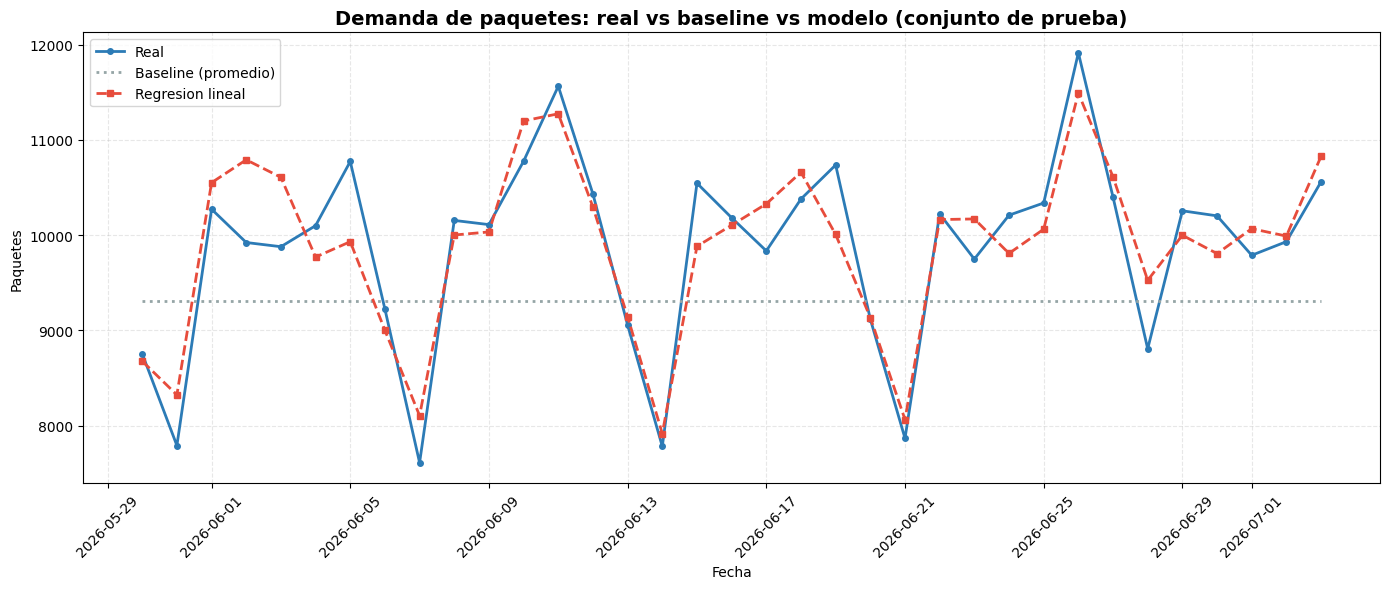

In [64]:

# ---------- Parte 2: grafico real vs baseline vs modelo ----------
# Utilizamos plot para dibujar las tres lineas en la misma grafica,
#  vemos cual se pega mas a la realidad.
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(fecha_test, y_test.values, label="Real", color="#2c7bb6", linewidth=2, marker="o", markersize=4)
ax.plot(fecha_test, pred_baseline, label="Baseline (promedio)", color="#95a5a6", linewidth=2, linestyle=":")
ax.plot(fecha_test, pred_modelo, label="Regresion lineal", color="#e74c3c", linewidth=2, linestyle="--", marker="s", markersize=4)
ax.set_title("Demanda de paquetes: real vs baseline vs modelo (conjunto de prueba)", fontsize=14, fontweight="bold")
ax.set_xlabel("Fecha")
ax.set_ylabel("Paquetes")
ax.grid(True, alpha=0.3, linestyle="--")
ax.legend(loc="upper left")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
# Linea azul: la demanda real de los 35 dias de prueba, sube y baja constantemente.
# Linea gris: el baseline, siempre en 9304 (el promedio del entrenamiento), no cambia nunca.
# Linea roja: la regresion lineal, sigue el patron de la azul en cierto modo (acompa;a las subidas y bajadas).

In [65]:
# ---------- Parte 3: explicacion ----------
# Esta explicacion se arma con los numeros reales de esta ejecucion, asi siempre coincide con metricas.json.
print("EXPLICACION: el modelo agrega valor?")
print("=" * 70)

print("\nOBSERVACIONES:")
print("   • El baseline siempre predice el promedio, se equivoca en promedio", round(mae_baseline, 2), "paquetes por dia.")
print("   • La regresion lineal se equivoca en promedio", round(mae_modelo, 2), "paquetes por dia.")
print("   • Eso es una mejora del", round(mejora_mae_pct, 2), "% en el MAE y un R2 de", round(r2_modelo, 4), ".")
print("   • El modelo sigue el patron de la demanda real, con desviaciones en dias especificos.")

print("\nCONCLUSION:")
if mae_modelo < mae_baseline:
    print("   • SI agrega valor, porque supera al baseline usando solo informacion que ya se conoce antes de predecir.")
else:
    print("   • NO agrega valor, porque no supera al baseline.")

print("\nLIMITACION:")
print("   • Es un modelo inicial. La prueba tiene pocos dias (", len(y_test), "), por eso el resultado es una estimacion y no una certeza.")

EXPLICACION: el modelo agrega valor?

OBSERVACIONES:
   • El baseline siempre predice el promedio, se equivoca en promedio 1001.34 paquetes por dia.
   • La regresion lineal se equivoca en promedio 340.13 paquetes por dia.
   • Eso es una mejora del 66.03 % en el MAE y un R2 de 0.8256 .
   • El modelo sigue el patron de la demanda real, con desviaciones en dias especificos.

CONCLUSION:
   • SI agrega valor, porque supera al baseline usando solo informacion que ya se conoce antes de predecir.

LIMITACION:
   • Es un modelo inicial. La prueba tiene pocos dias ( 35 ), por eso el resultado es una estimacion y no una certeza.


## P4 Justificacion tecnica

La prueba va de 2026-05-30 a 2026-07-03

MAE baseline = 1001.34, MAE modelo = 340.13, mejora = 66.03%.

No se entrena con datos del futuro porque al predecir el dia siguiente esos datos aun no existen (fuga de Informacion) y nos daria metricas falsas y un modelo poco practico.

Tambien se limita porque hay pocos datos (180 dias, 35 de prueba) y un modelo lineal no anticipa eventos atipicos: es una estimacion, no una certeza.

In [66]:
# DESCARGAR LOS ENTREGABLES:
# files.download
from google.colab import files
for nombre in ["predicciones.csv", "metricas.json", ]:
    files.download(nombre)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>